In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, make_scorer)

RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110

In [19]:
#Load_Data
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")   # 0 = malignant, 1 = benign

print("Shape of X:", X.shape)
print("\nClass counts:")
for label, count in y.value_counts().sort_index().items():
    print(f"  {label} ({data.target_names[label]}): {count}")
print("\nTotal missing values:", X.isnull().sum().sum())
print("\nFirst five feature names:")
for f in data.feature_names[:5]:
    print("  -", f)

Shape of X: (569, 30)

Class counts:
  0 (malignant): 212
  1 (benign): 357

Total missing values: 0

First five feature names:
  - mean radius
  - mean texture
  - mean perimeter
  - mean area
  - mean smoothness


In [20]:
X.describe().T[["mean", "std", "min", "max"]].head(10)

,mean,std,min,max
mean radius,14.127292,3.524049,6.98100,28.11000
mean texture,19.289649,4.301036,9.71000,39.28000
mean perimeter,91.969033,24.298981,43.79000,188.50000
mean area,654.889104,351.914129,143.50000,2501.00000
mean smoothness,0.096360,0.014064,0.05263,0.16340
mean compactness,0.104341,0.052813,0.01938,0.34540
mean concavity,0.088799,0.079720,0.00000,0.42680
mean concave points,0.048919,0.038803,0.00000,0.20120
mean symmetry,0.181162,0.027414,0.10600,0.30400
mean fractal dimension,0.062798,0.007060,0.04996,0.09744


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class proportions:\n", y_train.value_counts(normalize=True).round(3))
print("Test class proportions:\n", y_test.value_counts(normalize=True).round(3))

Train: (455, 30)  Test: (114, 30)
Train class proportions:
 target
1    0.626
0    0.374
Name: proportion, dtype: float64
Test class proportions:
 target
1    0.632
0    0.368
Name: proportion, dtype: float64


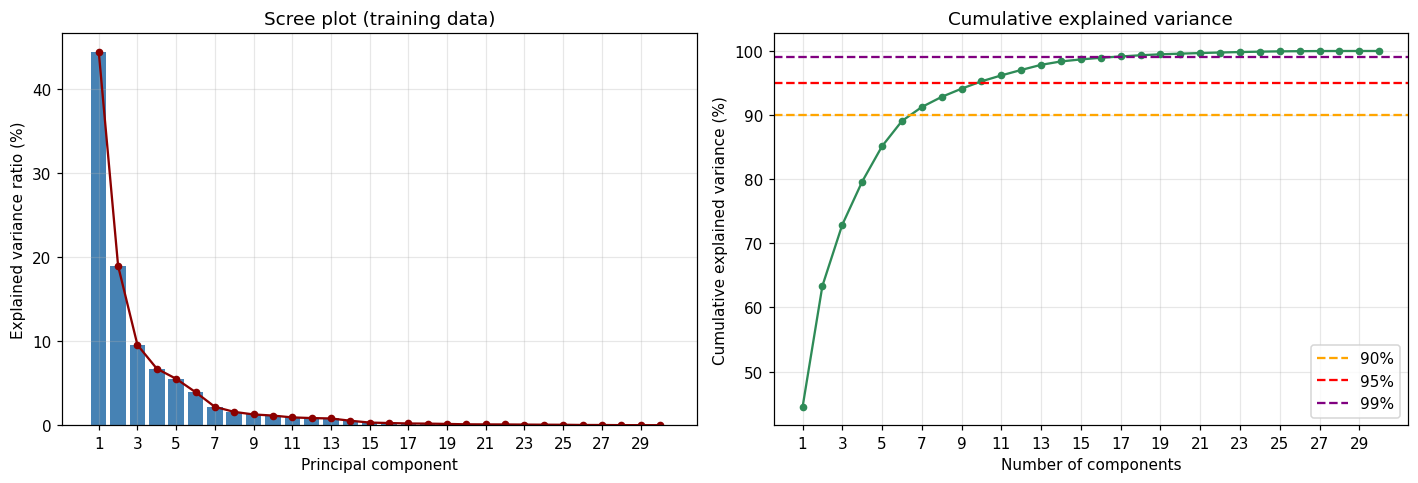

,PC,EVR (%),Cumulative (%)
0,1,44.41,44.41
1,2,18.94,63.36
2,3,9.54,72.90
3,4,6.72,79.63
4,5,5.52,85.14
5,6,3.93,89.08
6,7,2.18,91.26
7,8,1.58,92.84
8,9,1.28,94.12
9,10,1.15,95.27


In [22]:
scaler = StandardScaler().fit(X_train)
Z_train = scaler.transform(X_train)

pca_full = PCA(random_state=RANDOM_STATE).fit(Z_train)   # all 30 components
evr = pca_full.explained_variance_ratio_
cevr = np.cumsum(evr)
comps = np.arange(1, len(evr) + 1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].bar(comps, evr * 100, color="steelblue")
ax[0].plot(comps, evr * 100, "o-", color="darkred", markersize=4)
ax[0].set_xlabel("Principal component")
ax[0].set_ylabel("Explained variance ratio (%)")
ax[0].set_title("Scree plot (training data)")

ax[1].plot(comps, cevr * 100, "o-", color="seagreen", markersize=4)
for t, c in zip([90, 95, 99], ["orange", "red", "purple"]):
    ax[1].axhline(t, ls="--", color=c, label=f"{t}%")
ax[1].set_xlabel("Number of components")
ax[1].set_ylabel("Cumulative explained variance (%)")
ax[1].set_title("Cumulative explained variance")
ax[1].legend()
for a in ax:
    a.set_xticks(comps[::2])
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

pd.DataFrame({"PC": comps, "EVR (%)": (evr*100).round(2), "Cumulative (%)": (cevr*100).round(2)}).head(10)

In [23]:
for t in [0.90, 0.95, 0.99]:
    m = int(np.argmax(cevr >= t) + 1)
    print(f"{int(t*100)}% variance -> {m} components (actual: {cevr[m-1]*100:.2f}%)")

90% variance -> 7 components (actual: 91.26%)
95% variance -> 10 components (actual: 95.27%)
99% variance -> 17 components (actual: 99.15%)


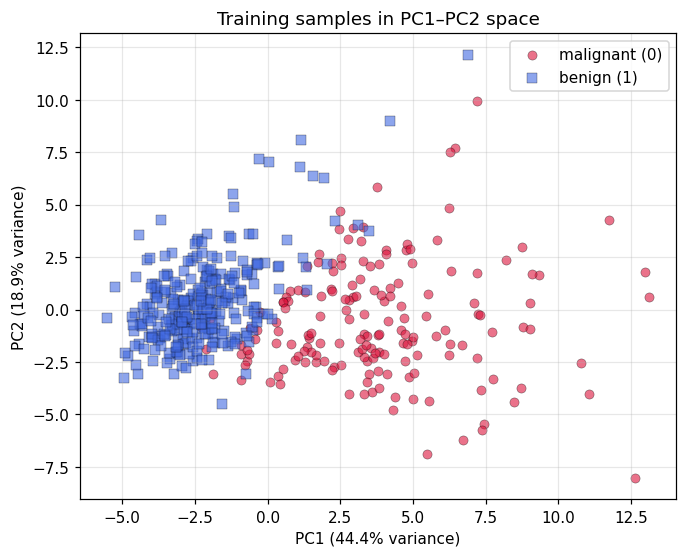

In [24]:
T_train = pca_full.transform(Z_train)

plt.figure(figsize=(7, 5.5))
for label, color, marker in [(0, "crimson", "o"), (1, "royalblue", "s")]:
    mask = (y_train.values == label)
    plt.scatter(T_train[mask, 0], T_train[mask, 1], c=color, marker=marker,
                alpha=0.6, edgecolor="k", linewidth=0.3,
                label=f"{data.target_names[label]} ({label})")
plt.xlabel(f"PC1 ({evr[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({evr[1]*100:.1f}% variance)")
plt.title("Training samples in PC1–PC2 space")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Top 5 features by |loading| on PC1:
                         PC1
mean concave points   0.2614
mean concavity        0.2578
worst concave points  0.2499
mean compactness      0.2422
worst perimeter       0.2349

Top 5 features by |loading| on PC2:
                            PC2
mean fractal dimension   0.3646
fractal dimension error  0.2783
worst fractal dimension  0.2741
mean radius             -0.2387
compactness error        0.2348


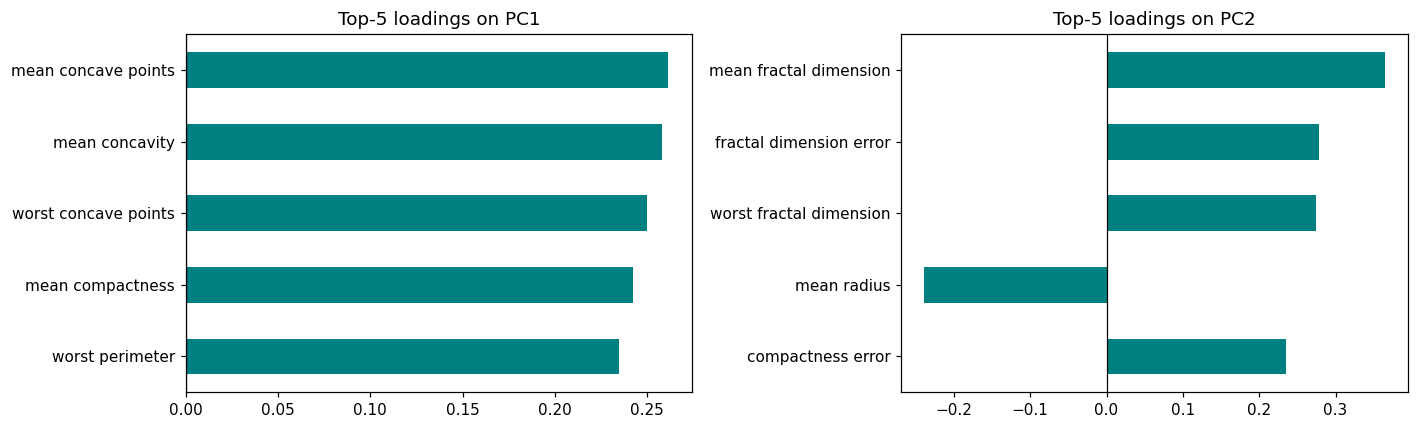

In [25]:
loadings = pd.DataFrame(pca_full.components_[:2].T,
                        index=data.feature_names, columns=["PC1", "PC2"])

for pc in ["PC1", "PC2"]:
    top = loadings[pc].abs().sort_values(ascending=False).head(5).index
    print(f"\nTop 5 features by |loading| on {pc}:")
    print(loadings.loc[top, [pc]].round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for i, pc in enumerate(["PC1", "PC2"]):
    top = loadings[pc].abs().sort_values(ascending=False).head(5).index
    loadings.loc[top, pc].plot.barh(ax=ax[i], color="teal")
    ax[i].set_title(f"Top-5 loadings on {pc}")
    ax[i].invert_yaxis()
    ax[i].axvline(0, color="k", lw=0.8)
plt.tight_layout()
plt.show()

**Discussion of loadings**
- **PC1** loads with similar weights and the same sign on many size and shape-irregularity features (concave points, concavity, compactness, perimeter, radius). It acts as an overall "nucleus size/irregularity" axis. Malignant samples sit at one end of PC1, which explains the visible class separation in the scatter plot.
- **PC2** contrasts size features against texture/fractal-dimension and smoothness features. It captures shape complexity that is roughly independent of size.

**Limitations**
- Signs are arbitrary: multiplying an eigenvector by −1 gives the same solution, so only relative signs *within* a component matter.
- Loadings describe how features contribute to *variance*, not to diagnosis. A feature with a large loading may not be predictive, and a predictive feature may load weakly.
- Each PC mixes many correlated features (e.g. radius, perimeter, area), so attributing meaning to any single feature is risky.
- Loadings depend on standardization and on the training sample.

In [26]:
def evaluate(model, name):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])  # rows: true M, B ; cols: pred M, B
    tp, fn, fp, tn = cm.ravel()
    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (M)": precision_score(y_test, y_pred, pos_label=0),
        "Sensitivity (M)": recall_score(y_test, y_pred, pos_label=0),
        "Specificity": tn / (tn + fp),
        "F1 (M)": f1_score(y_test, y_pred, pos_label=0),
    }
    return metrics, cm

def plot_cms(cms, titles):
    fig, axes = plt.subplots(1, len(cms), figsize=(5 * len(cms), 4))
    axes = np.atleast_1d(axes)
    for ax, cm, t in zip(axes, cms, titles):
        ConfusionMatrixDisplay(cm, display_labels=["Malignant (0)", "Benign (1)"]).plot(
            ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()

Components kept by PCA(0.95): 10


,Accuracy,Precision (M),Sensitivity (M),Specificity,F1 (M)
Model,,,,,
Scaled KNN (k=5),0.9561,0.9512,0.9286,0.9722,0.9398
PCA 95% + KNN (k=5),0.9561,0.9512,0.9286,0.9722,0.9398


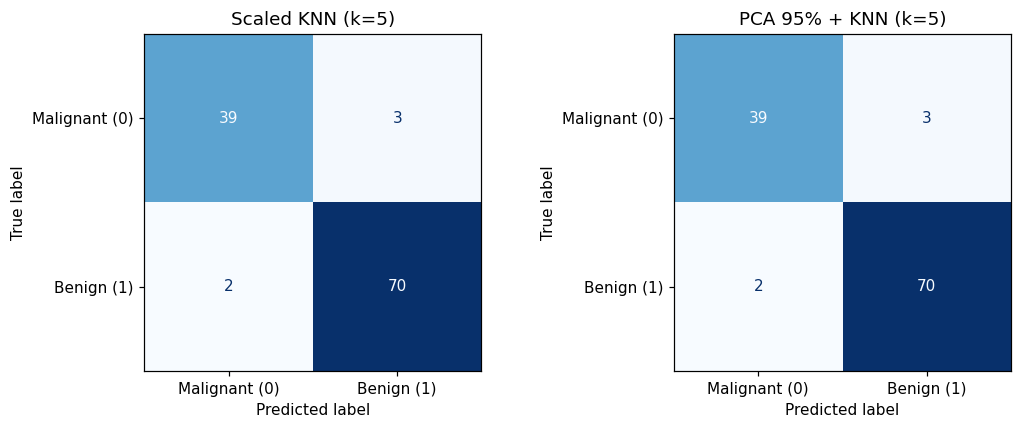

In [27]:
baseline = Pipeline([("scaler", StandardScaler()),
                     ("knn", KNeighborsClassifier(n_neighbors=5))])

pca_knn = Pipeline([("scaler", StandardScaler()),
                    ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
                    ("knn", KNeighborsClassifier(n_neighbors=5))])

baseline.fit(X_train, y_train)
pca_knn.fit(X_train, y_train)
print("Components kept by PCA(0.95):", pca_knn.named_steps["pca"].n_components_)

m1, cm1 = evaluate(baseline, "Scaled KNN (k=5)")
m2, cm2 = evaluate(pca_knn, "PCA 95% + KNN (k=5)")
display(pd.DataFrame([m1, m2]).set_index("Model").round(4))
plot_cms([cm1, cm2], ["Scaled KNN (k=5)", "PCA 95% + KNN (k=5)"])

In [28]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"f1_malignant": make_scorer(f1_score, pos_label=0),
           "sens_malignant": make_scorer(recall_score, pos_label=0),
           "accuracy": "accuracy"}
k_values = list(range(1, 32, 2))

# Baseline: tune k only
gs_base = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())]),
    {"knn__n_neighbors": k_values},
    cv=cv, scoring=scoring, refit="f1_malignant")
gs_base.fit(X_train, y_train)

# PCA + KNN: tune k and n_components
gs_pca = GridSearchCV(
    Pipeline([("scaler", StandardScaler()),
              ("pca", PCA(random_state=RANDOM_STATE)),
              ("knn", KNeighborsClassifier())]),
    {"pca__n_components": [2, 3, 5, 7, 10, 15, 20, 30], "knn__n_neighbors": k_values},
    cv=cv, scoring=scoring, refit="f1_malignant")
gs_pca.fit(X_train, y_train)

for name, gs in [("Baseline", gs_base), ("PCA+KNN", gs_pca)]:
    i = gs.best_index_
    r = gs.cv_results_
    print(f"{name}: best params = {gs.best_params_}")
    print(f"   CV F1(M) = {r['mean_test_f1_malignant'][i]:.4f} | "
          f"CV Sens(M) = {r['mean_test_sens_malignant'][i]:.4f} | "
          f"CV Acc = {r['mean_test_accuracy'][i]:.4f}")

Baseline: best params = {'knn__n_neighbors': 9}
   CV F1(M) = 0.9517 | CV Sens(M) = 0.9294 | CV Acc = 0.9648
PCA+KNN: best params = {'knn__n_neighbors': 9, 'pca__n_components': 15}
   CV F1(M) = 0.9548 | CV Sens(M) = 0.9353 | CV Acc = 0.9670


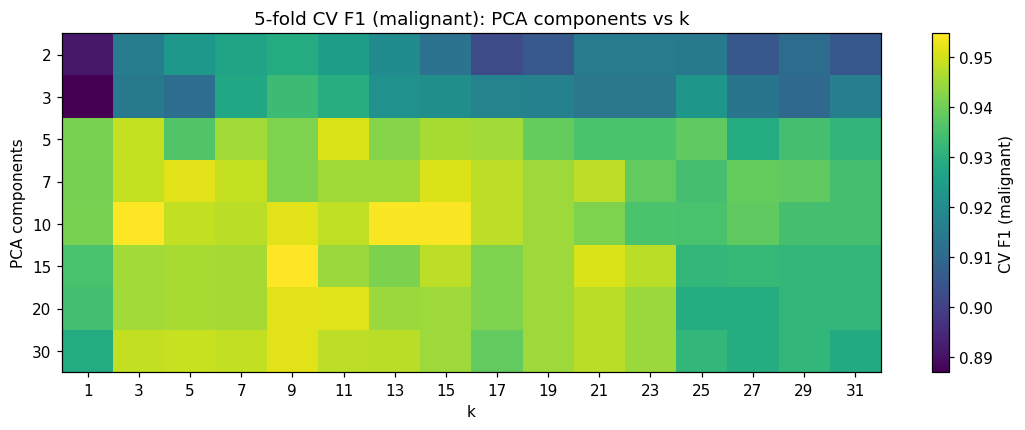

In [29]:
res = pd.DataFrame(gs_pca.cv_results_)
heat = res.pivot(index="param_pca__n_components", columns="param_knn__n_neighbors",
                 values="mean_test_f1_malignant")
plt.figure(figsize=(12, 4))
plt.imshow(heat, aspect="auto", cmap="viridis")
plt.colorbar(label="CV F1 (malignant)")
plt.yticks(range(len(heat.index)), heat.index)
plt.xticks(range(len(heat.columns)), heat.columns)
plt.ylabel("PCA components")
plt.xlabel("k")
plt.title("5-fold CV F1 (malignant): PCA components vs k")
plt.show()

,Accuracy,Precision (M),Sensitivity (M),Specificity,F1 (M)
Model,,,,,
Scaled KNN (k=5),0.9561,0.9512,0.9286,0.9722,0.9398
PCA 95% + KNN (k=5),0.9561,0.9512,0.9286,0.9722,0.9398
Tuned KNN (k=9),0.9737,1.0000,0.9286,1.0000,0.9630
Tuned PCA(15) + KNN (k=9),0.9649,0.9750,0.9286,0.9861,0.9512


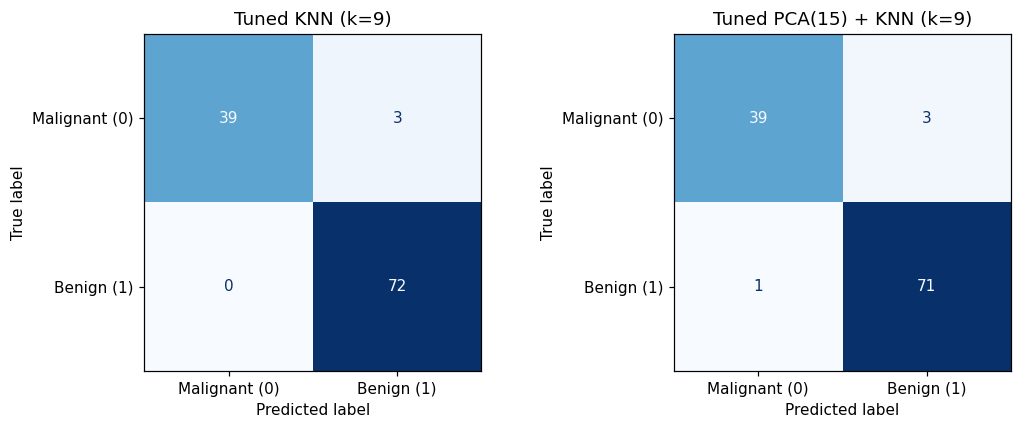

In [30]:
m3, cm3 = evaluate(gs_base.best_estimator_, f"Tuned KNN (k={gs_base.best_params_['knn__n_neighbors']})")
m4, cm4 = evaluate(gs_pca.best_estimator_,
                   f"Tuned PCA({gs_pca.best_params_['pca__n_components']}) + KNN "
                   f"(k={gs_pca.best_params_['knn__n_neighbors']})")

comparison = pd.DataFrame([m1, m2, m3, m4]).set_index("Model").round(4)
display(comparison)
plot_cms([cm3, cm4], [m3["Model"], m4["Model"]])

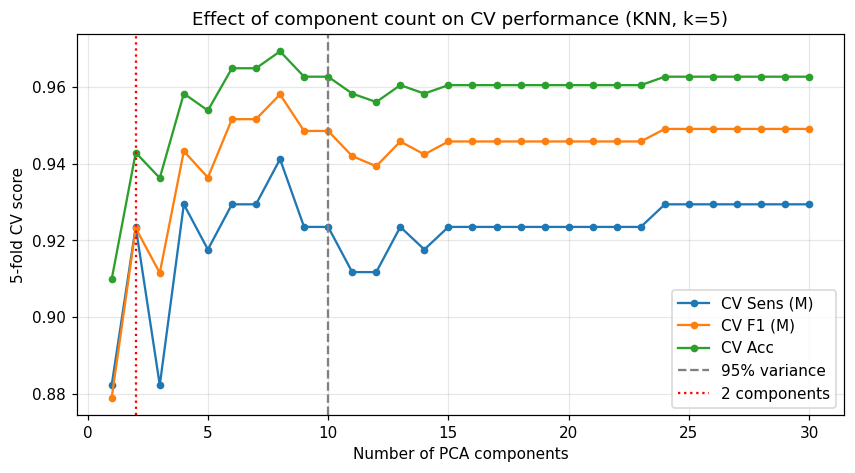

In [31]:
rows = []
for n in range(1, 31):
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("pca", PCA(n_components=n, random_state=RANDOM_STATE)),
                     ("knn", KNeighborsClassifier(n_neighbors=5))])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"n_components": n,
                 "CV Sens (M)": r["test_sens_malignant"].mean(),
                 "CV F1 (M)": r["test_f1_malignant"].mean(),
                 "CV Acc": r["test_accuracy"].mean()})
sweep = pd.DataFrame(rows)

plt.figure(figsize=(9, 4.5))
for col in ["CV Sens (M)", "CV F1 (M)", "CV Acc"]:
    plt.plot(sweep["n_components"], sweep[col], "o-", markersize=4, label=col)
plt.axvline(pca_knn.named_steps["pca"].n_components_, ls="--", color="gray", label="95% variance")
plt.axvline(2, ls=":", color="red", label="2 components")
plt.xlabel("Number of PCA components")
plt.ylabel("5-fold CV score")
plt.title("Effect of component count on CV performance (KNN, k=5)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [32]:
def make(clf, n=None):
    steps = [("scaler", StandardScaler())]
    if n is not None:
        steps.append(("pca", PCA(n_components=n, random_state=RANDOM_STATE)))
    steps.append(("clf", clf))
    return Pipeline(steps)

configs = {"No PCA": None, "PCA 2 comps": 2, "PCA 95%": 0.95}
results = []
for clf_name, clf in [("KNN (k=5)", KNeighborsClassifier(n_neighbors=5)), ("Gaussian NB", GaussianNB())]:
    for cfg_name, n in configs.items():
        model = make(clf, n)
        cv_sens = cross_validate(model, X_train, y_train, cv=cv,
                                 scoring=scoring)["test_sens_malignant"].mean()
        model.fit(X_train, y_train)
        m, _ = evaluate(model, f"{clf_name} | {cfg_name}")
        m["CV Sens (M)"] = cv_sens
        results.append(m)

challenge = pd.DataFrame(results).set_index("Model").round(4)
challenge

,Accuracy,Precision (M),Sensitivity (M),Specificity,F1 (M),CV Sens (M)
Model,,,,,,
KNN (k=5) | No PCA,0.9561,0.9512,0.9286,0.9722,0.9398,0.9294
KNN (k=5) | PCA 2 comps,0.9211,0.8837,0.9048,0.9306,0.8941,0.9235
KNN (k=5) | PCA 95%,0.9561,0.9512,0.9286,0.9722,0.9398,0.9235
Gaussian NB | No PCA,0.9298,0.9048,0.9048,0.9444,0.9048,0.9000
Gaussian NB | PCA 2 comps,0.9123,0.8810,0.8810,0.9306,0.8810,0.8529
Gaussian NB | PCA 95%,0.9211,0.9024,0.8810,0.9444,0.8916,0.8706


**Why a 2D plot is useful for visualization but insufficient for classification:**
Two components retain only about 63% of the training variance. The PC1–PC2 plot shows the overall structure clearly (malignant vs benign spread along PC1), but the overlap region contains the hard cases, and the information that separates them lives in the discarded components. In my results, 2-component PCA gave lower test sensitivity and F1 than both no-PCA and 95% PCA, for KNN and for Gaussian NB. PCA also picks axes by variance, not by class separation, so even the components it keeps are not tuned for diagnosis.

## Technical Discussion

**1. Variance retained vs prediction quality.**
Seven components keep 90% of the variance, 10 keep 95%, and 17 keep 99%. Yet PCA(95%)+KNN performed about the same as the scaled baseline on the test set (identical confusion matrix at k=5). After tuning, the baseline was marginally better. High explained variance does not guarantee better classification because PCA is unsupervised: it keeps high-variance directions, which are not necessarily the most discriminative. The component sweep shows performance plateaus after a few components and does not rise monotonically with retained variance. Low-variance directions can still carry class information, and high-variance directions can contain noise irrelevant to diagnosis.

**2. Computational trade-offs.**
KNN computes distances in feature space at prediction time, so its cost scales with dimensionality, O(n·p) per query. Going from 30 to 10 dimensions cuts this roughly threefold and reduces storage. It can also ease the curse of dimensionality and remove the redundancy of highly correlated features (radius/perimeter/area). The cost is an extra fitted step, one more hyperparameter (number of components), and loss of direct feature interpretability. With 569 × 30 data the savings are negligible. They matter for high-dimensional biomedical data such as gene expression, spectra or images.

**3. Biomedical interpretation.**
PC1 is essentially a nucleus size/irregularity axis. That matches clinical intuition: larger, more irregular nuclei with more concave points suggest malignancy. But PCs are mixtures of features, so they are harder to explain to clinicians than the original measurements. In screening, a missed malignancy (false negative) is far costlier than a false alarm, so **malignant sensitivity** matters more than accuracy. Both tuned models missed about 3 of 42 malignant test cases. Future work could use class-weighting or threshold adjustment to raise sensitivity, or supervised projections such as LDA.

**4. Conclusion.**
PCA is a valuable tool for visualization and compression, but on this dataset it does not improve KNN accuracy. The component count should be selected by cross-validated task metrics (here, malignant F1/sensitivity) inside a pipeline, not by a fixed variance threshold alone.


## 7. Viva / Discussion Questions

### 1. Is PCA supervised or unsupervised? Does it use diagnosis labels to choose principal axes?

PCA is an **unsupervised** dimensionality reduction technique. It identifies directions of maximum variance in the dataset without considering the diagnosis labels (malignant or benign). Therefore, the principal components capture variation in the features, but not necessarily the variation that best separates the two classes.

### 2. Why can a feature with a large numeric scale dominate PCA without standardization?

PCA identifies directions with the highest variance. Features with larger numerical scales usually have larger variances and can dominate the principal components, even if they are not more informative. Standardization transforms features to have a mean of 0 and a standard deviation of 1, allowing them to contribute on a comparable scale.

### 3. What does it mean when PC1 explains 45% of the variance?

It means that the first principal component captures approximately **45% of the total variance** in the original standardized dataset. PC1 represents the direction along which the data varies the most. However, this does not mean that PC1 contains 45% of the information needed for classification or diagnosis.

### 4. Why can PCA improve, worsen, or leave classifier accuracy unchanged?

PCA can **improve accuracy** by removing noise and redundant features, potentially reducing overfitting. It can **worsen accuracy** if the discarded components contain information useful for distinguishing classes. Accuracy may also **remain unchanged** when the retained components preserve most of the discriminative information.

In our experiment, KNN with and without 95%-variance PCA achieved the same accuracy of **95.61%**, showing that dimensionality reduction did not improve classification performance.

### 5. Why must PCA be included inside the cross-validation pipeline?

PCA must be included inside the cross-validation pipeline to **prevent data leakage**. If PCA is fitted before cross-validation, it uses information from samples that will later belong to validation folds, potentially producing overly optimistic results.

Using `Pipeline(StandardScaler(), PCA(), KNeighborsClassifier())` ensures that scaling and PCA are fitted only on the training portion of each fold, while the validation portion is transformed using those fitted parameters.

### 6. Why can the signs of PCA components differ across implementations?

Eigenvectors can be multiplied by -1 without changing their mathematical meaning. Therefore, different PCA implementations may return principal components with opposite signs while representing the same directions and explaining the same amount of variance. The sign itself does not affect the underlying PCA solution.

### 7. What is the difference between variance explained and clinical importance?

**Explained variance** measures how much of the dataset's overall variation is captured by a principal component, while **clinical importance** refers to how useful a feature or pattern is for diagnosis or predicting a medical condition.

A component can explain a large amount of variance without being useful for distinguishing malignant from benign tumors. Similarly, a low-variance component may contain clinically relevant information. Therefore, high explained variance does not necessarily indicate high diagnostic value.

### 8. Why is malignant sensitivity often more informative than accuracy alone?

Malignant sensitivity measures the proportion of actual malignant cases correctly identified by the model:

**Sensitivity = TP / (TP + FN)**

In medical diagnosis, a false negative means a malignant case is incorrectly classified as benign, potentially delaying diagnosis and treatment.

A model can achieve high overall accuracy while still missing important malignant cases, especially when the classes are imbalanced.

In our experiment, the tuned models achieved **92.86% malignant sensitivity**, meaning that **39 out of 42 malignant cases were correctly identified**, while 3 were missed. This highlights why sensitivity must be considered alongside accuracy when evaluating biomedical classifiers.
